In [4]:
import numpy as np
import pandas as pd

files = {1: "round_k1.csv", 10: "moderate_k10.csv", 100: "narrow_k100.csv"}
w0 = np.zeros(2)                      # start at (0, 0)

for kappa, name in files.items():
    d = pd.read_csv(name)
    X = d[["x1", "x2"]].values        # features (ignore sample_id)
    y = d["y"].values
    n = len(X)

    f0 = 0.5 * np.mean((X @ w0 - y) ** 2)      # starting loss
    g0 = X.T @ (X @ w0 - y) / n                # starting gradient
    ratio = abs(g0[0]) / abs(g0[1])            # w1 pull vs w2 pull

    print(f"kappa={kappa:>3}  f(0)={f0:.3f}  g0=({g0[0]:.3f}, {g0[1]:.3f})  ratio={ratio:.1f}x")

kappa=  1  f(0)=6.500  g0=(-3.000, -2.000)  ratio=1.5x
kappa= 10  f(0)=4.700  g0=(-3.000, -0.200)  ratio=15.0x
kappa=100  f(0)=4.520  g0=(-3.000, -0.020)  ratio=150.0x


## Final phase: GD and L-BFGS paths on the loss contours (preliminary)

For κ = 1, 10 and 100: the loss contours, the start (0,0), the minimum (3,2), the full-batch GD path and the L-BFGS path (scipy L-BFGS-B, memory 10). Same setup as before: stop when the gradient norm is below 1e-6.
GD needs 1 / 75 / 746 steps and L-BFGS needs 2 / 6 / 5. These match the mid-project results.
The L-BFGS path will be replaced by Saranya's path (lbfgs_path.csv) once it is checked.
Used for slide 2 and the report figure fig_contours_gd.png.

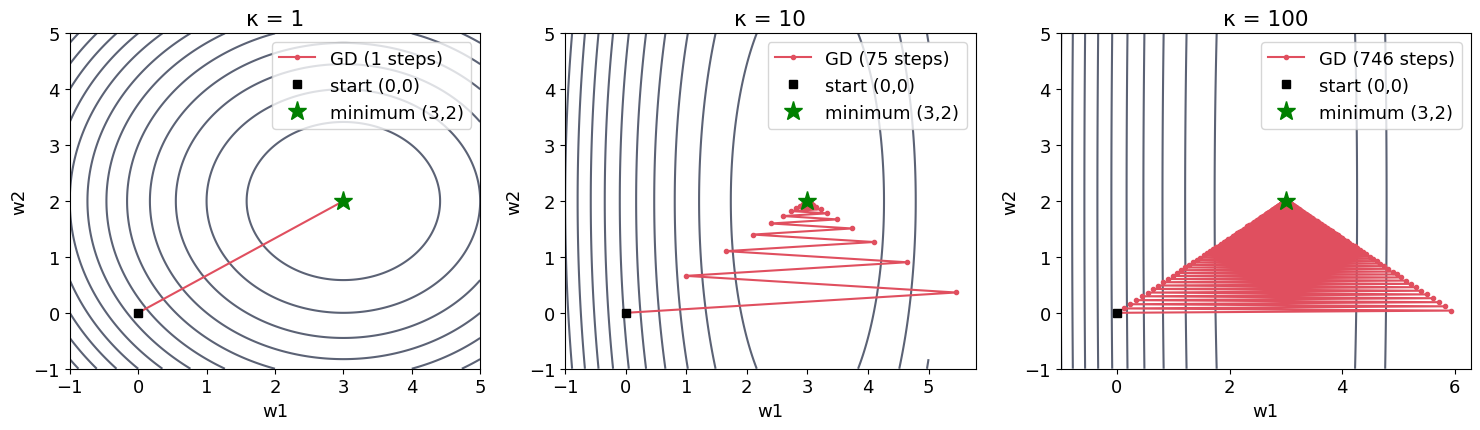

In [5]:
import numpy as np, matplotlib.pyplot as plt
W_STAR = np.array([3., 2.])

def make(k, n=200, seed=42):
    r = np.random.default_rng(seed); A = r.standard_normal((n, 2)); A -= A.mean(0)
    Q, _ = np.linalg.qr(A); X = np.sqrt(n) * Q @ np.diag([1, 1/np.sqrt(k)])
    return X, X @ W_STAR

def gd_path(X, y, tol=1e-6):
    n = len(y); lam = np.linalg.eigvalsh(X.T @ X / n); a = 2 / (lam[0] + lam[-1])
    w = np.zeros(2); path = [w.copy()]
    while np.linalg.norm(X.T @ (X @ w - y) / n) >= tol:
        w = w - a * X.T @ (X @ w - y) / n; path.append(w.copy())
    return np.array(path)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, (1, 10, 100)):
    X, y = make(k); P = gd_path(X, y)
    g1, g2 = np.meshgrid(np.linspace(-1, 5, 300), np.linspace(-1, 5, 300))
    ax.contour(g1, g2, 0.5*((g1-3)**2 + (g2-2)**2/k), levels=12, colors="#5B6275")
    ax.plot(P[:, 0], P[:, 1], "o-", ms=3, color="#E04F5F", label=f"GD ({len(P)-1} steps)")
    ax.plot(0, 0, "ks", label="start (0,0)"); ax.plot(3, 2, "g*", ms=14, label="minimum (3,2)")
    ax.set_title(f"κ = {k}"); ax.set_xlabel("w1"); ax.set_ylabel("w2"); ax.legend()
plt.tight_layout(); plt.savefig("fig_contours_gd.png", dpi=300)